# Data Understanding

In [5]:
import pandas as pd

df = pd.read_csv("../data/app_user_behavior_dataset.csv")

print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData Info:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Shape: (50000, 25)

Columns:
['user_id', 'age', 'gender', 'country', 'device_type', 'app_version', 'sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes', 'feature_clicks_per_session', 'notifications_opened_per_week', 'in_app_search_count', 'pages_viewed_per_session', 'crash_events_last_30_days', 'support_tickets_raised', 'days_since_last_login', 'subscription_type', 'ads_clicked_last_30_days', 'content_downloads', 'social_shares', 'rating_given', 'churn_risk_score', 'engagement_score', 'account_age_days', 'marketing_source']

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   user_id                        50000 non-null  int64  
 1   age                            50000 non-null  int64  
 2   gender                         50000 non-null  object 
 3   country                  

In [3]:
# Check completely duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Check whether any user appears more than once
print("\nDuplicate user IDs:", df["user_id"].duplicated().sum())

# Count unique categories in each categorical column
print("\nCategorical columns:")
print(df[["gender", "country", "device_type", "subscription_type", "marketing_source", "app_version"]].nunique())

Duplicate rows: 0

Duplicate user IDs: 0

Categorical columns:
gender               3
country              7
device_type          3
subscription_type    3
marketing_source     5
app_version          5
dtype: int64


In [4]:
# Get basic statistics for all numerical columns
print(df.describe())

             user_id           age   app_version  sessions_per_week  \
count   50000.000000  50000.000000  50000.000000       50000.000000   
mean   124999.500000     38.513040      1.476126           7.999680   
std     14433.901067     12.094948      0.470158           2.829438   
min    100000.000000     18.000000      1.000000           0.000000   
25%    112499.750000     28.000000      1.100000           6.000000   
50%    124999.500000     39.000000      1.200000           8.000000   
75%    137499.250000     49.000000      2.000000          10.000000   
max    149999.000000     59.000000      2.100000          26.000000   

       avg_session_duration_min  daily_active_minutes  \
count              50000.000000          50000.000000   
mean                  13.149842             45.164537   
std                    8.946944             19.505118   
min                    0.060000              5.000000   
25%                    6.570000             31.650000   
50%               

In [5]:
# Check the actual values in categorical columns
categorical_cols = [
    "gender",
    "country",
    "device_type",
    "subscription_type",
    "marketing_source",
    "app_version"
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


gender:
['Female' 'Male' 'Other']

country:
['India' 'UK' 'Australia' 'Germany' 'Singapore' 'Canada' 'USA']

device_type:
['iOS' 'Android' 'Web']

subscription_type:
['Basic' 'Free' 'Premium']

marketing_source:
['Referral' 'Email Campaign' 'Google Ads' 'Organic' 'Facebook Ads']

app_version:
[2.1 1.  1.2 2.  1.1]


# Data Cleaning

In [6]:
# Check the rating column
print(df["rating_given"].describe())

# Check missing values
print("\nMissing values:", df["rating_given"].isnull().sum())

# Check all unique rating values
print("\nUnique values:", df["rating_given"].unique())


count    44978.000000
mean         3.630664
std          1.087339
min          1.000000
25%          3.000000
50%          4.000000
75%          4.000000
max          5.000000
Name: rating_given, dtype: float64

Missing values: 5022

Unique values: [nan  3.  2.  5.  4.  1.]


In [7]:
# Find the median rating
median_rating = df["rating_given"].median()

# Fill missing ratings with the median
df["rating_given"] = df["rating_given"].fillna(median_rating)

# Verify that missing values are gone
print("Missing ratings:", df["rating_given"].isnull().sum())

Missing ratings: 0


In [8]:
# Numerical columns we want to validate
numeric_cols = [
    "age",
    "sessions_per_week",
    "avg_session_duration_min",
    "daily_active_minutes",
    "feature_clicks_per_session",
    "notifications_opened_per_week",
    "in_app_search_count",
    "pages_viewed_per_session",
    "crash_events_last_30_days",
    "support_tickets_raised",
    "days_since_last_login",
    "ads_clicked_last_30_days",
    "content_downloads",
    "social_shares",
    "rating_given",
    "churn_risk_score",
    "engagement_score",
    "account_age_days"
]

# Show minimum and maximum values
print(df[numeric_cols].agg(["min", "max"]).T)

                                 min      max
age                            18.00    59.00
sessions_per_week               0.00    26.00
avg_session_duration_min        0.06    91.40
daily_active_minutes            5.00   129.13
feature_clicks_per_session      1.00    28.00
notifications_opened_per_week   0.00    16.00
in_app_search_count             0.00    19.00
pages_viewed_per_session        3.00    24.00
crash_events_last_30_days       0.00     5.00
support_tickets_raised          0.00     4.00
days_since_last_login           0.00    44.00
ads_clicked_last_30_days        0.00    19.00
content_downloads               0.00    13.00
social_shares                   0.00    11.00
rating_given                    1.00     5.00
churn_risk_score                0.00     1.00
engagement_score               10.00   100.00
account_age_days                7.00  1199.00


In [9]:
# Calculate Q1 (25th percentile)
Q1 = df[numeric_cols].quantile(0.25)

# Calculate Q3 (75th percentile)
Q3 = df[numeric_cols].quantile(0.75)

# Calculate the Interquartile Range
IQR = Q3 - Q1

# Define lower and upper limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Count possible outliers in each column
outliers = ((df[numeric_cols] < lower) | 
            (df[numeric_cols] > upper)).sum()

print(outliers.sort_values(ascending=False))

support_tickets_raised           8910
rating_given                     2518
avg_session_duration_min         1572
in_app_search_count              1054
feature_clicks_per_session        745
notifications_opened_per_week     660
content_downloads                 622
crash_events_last_30_days         398
social_shares                     219
daily_active_minutes              181
sessions_per_week                 181
engagement_score                  167
ads_clicked_last_30_days           70
churn_risk_score                    0
age                                 0
days_since_last_login               0
pages_viewed_per_session            0
account_age_days                    0
dtype: int64


# EDA

In [5]:
# Main behavioral features
behavior_cols = [
    "sessions_per_week",
    "avg_session_duration_min",
    "daily_active_minutes",
    "feature_clicks_per_session",
    "notifications_opened_per_week",
    "in_app_search_count",
    "pages_viewed_per_session",
    "content_downloads",
    "social_shares",
    "engagement_score",
    "churn_risk_score"
]

# Summary statistics
print(df[behavior_cols].describe())

       sessions_per_week  avg_session_duration_min  daily_active_minutes  \
count       50000.000000              50000.000000          50000.000000   
mean            7.999680                 13.149842             45.164537   
std             2.829438                  8.946944             19.505118   
min             0.000000                  0.060000              5.000000   
25%             6.000000                  6.570000             31.650000   
50%             8.000000                 11.240000             45.210000   
75%            10.000000                 17.570000             58.440000   
max            26.000000                 91.400000            129.130000   

       feature_clicks_per_session  notifications_opened_per_week  \
count                50000.000000                    50000.00000   
mean                    12.013920                        4.99662   
std                      3.480289                        2.23518   
min                      1.000000          

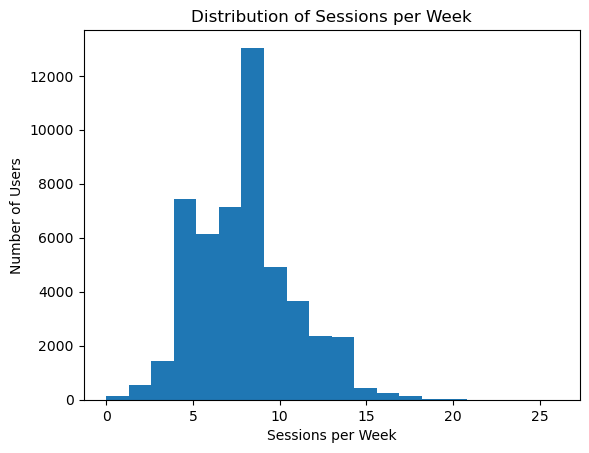

In [11]:
import matplotlib.pyplot as plt

# Plot the distribution of sessions per week
plt.hist(df['sessions_per_week'],bins = 20)

plt.xlabel("Sessions per Week")
plt.ylabel("Number of Users")
plt.title("Distribution of Sessions per Week")

plt.show()

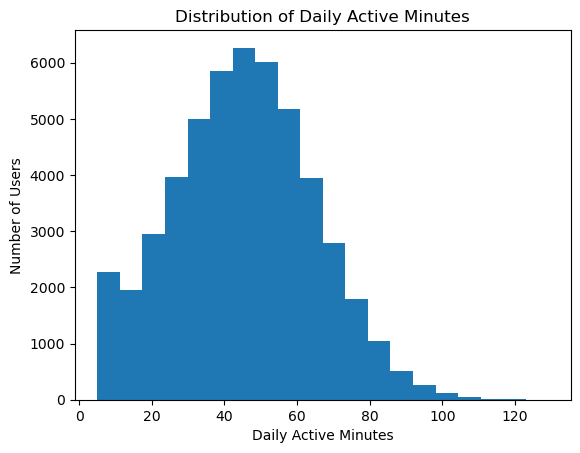

In [13]:
# Distribution of daily active minutes
plt.hist(df['daily_active_minutes'], bins=20)

plt.xlabel("Daily Active Minutes")
plt.ylabel("Number of Users")
plt.title("Distribution of Daily Active Minutes")

plt.show()

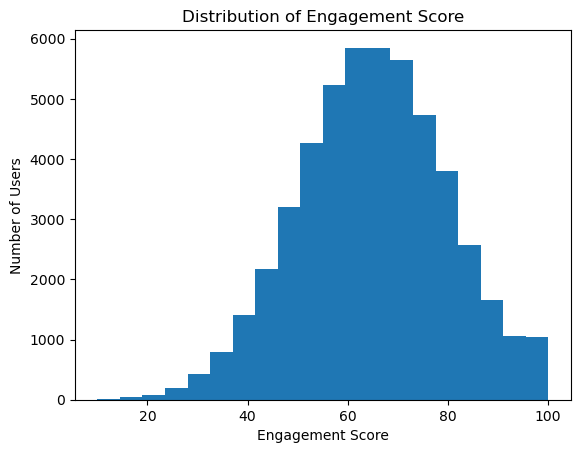

In [12]:
# Distribution of engagement scores
plt.hist(df["engagement_score"], bins=20)

plt.xlabel("Engagement Score")
plt.ylabel("Number of Users")
plt.title("Distribution of Engagement Score")

plt.show()


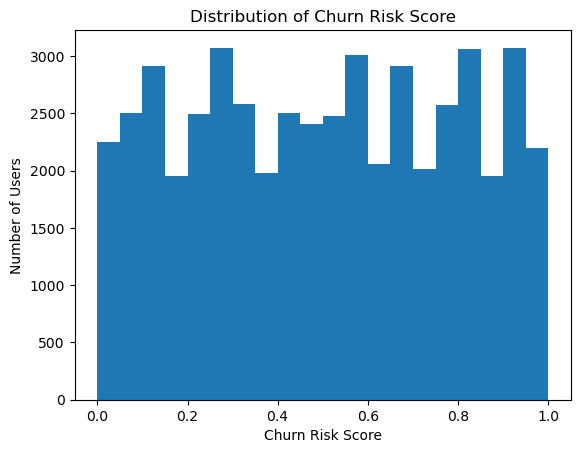

In [13]:
# Distribution of churn risk score
plt.hist(df["churn_risk_score"], bins=20)

plt.xlabel("Churn Risk Score")
plt.ylabel("Number of Users")
plt.title("Distribution of Churn Risk Score")

plt.show()

In [14]:
# Select the behavioral columns and calculate correlation

correlation = df[behavior_cols].corr()
print(correlation)

                               sessions_per_week  avg_session_duration_min  \
sessions_per_week                       1.000000                  0.000290   
avg_session_duration_min                0.000290                  1.000000   
daily_active_minutes                    0.000492                 -0.003850   
feature_clicks_per_session             -0.001492                 -0.000953   
notifications_opened_per_week           0.006891                 -0.000854   
in_app_search_count                     0.001794                 -0.001568   
pages_viewed_per_session               -0.001751                  0.005117   
content_downloads                       0.000543                  0.002493   
social_shares                          -0.001845                  0.001301   
engagement_score                       -0.000794                 -0.004696   
churn_risk_score                       -0.006672                 -0.005172   

                               daily_active_minutes  \
sessions

In [15]:
# Count users in each subscription type
print(df["subscription_type"].value_counts())

subscription_type
Free       30088
Basic      12495
Premium     7417
Name: count, dtype: int64


In [16]:
# Count users by device type
print(df["device_type"].value_counts())

device_type
Android    27315
iOS        17662
Web         5023
Name: count, dtype: int64


In [17]:
# Count users by gender
print(df["gender"].value_counts())

gender
Female    23994
Male      23936
Other      2070
Name: count, dtype: int64


In [18]:
# Count users by country
print(df["country"].value_counts())

country
India        22550
USA           9115
UK            5043
Canada        3853
Australia     3498
Germany       3425
Singapore     2516
Name: count, dtype: int64


In [19]:
# Count users by marketing source
print(df["marketing_source"].value_counts())

marketing_source
Organic           17539
Google Ads        12468
Referral           7539
Facebook Ads       7463
Email Campaign     4991
Name: count, dtype: int64


# Feature Selection

In [6]:
# Select features that describe user behavior
behavior_cols = [
    "sessions_per_week",
    "avg_session_duration_min",
    "daily_active_minutes",
    "feature_clicks_per_session",
    "notifications_opened_per_week",
    "in_app_search_count",
    "pages_viewed_per_session",
    "content_downloads",
    "social_shares",
    "engagement_score",
    "churn_risk_score"
]

# Create a new DataFrame with only these features
behavior_df = df[behavior_cols]

print("Selected features:")
print(behavior_df.columns.tolist())

Selected features:
['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes', 'feature_clicks_per_session', 'notifications_opened_per_week', 'in_app_search_count', 'pages_viewed_per_session', 'content_downloads', 'social_shares', 'engagement_score', 'churn_risk_score']


In [ ]:
df[behavior_cols]

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
0,5,3.41,52.71,13,5,8,8,5,2,55.79,0.31
1,8,24.44,42.03,7,7,3,7,3,3,82.39,0.87
2,12,5.34,76.69,7,5,2,21,6,1,42.49,0.63
3,5,3.98,65.38,16,8,4,13,3,1,62.81,0.43
4,10,12.85,57.06,13,7,3,15,4,2,38.21,0.43
...,...,...,...,...,...,...,...,...,...,...,...
49995,10,8.68,70.21,15,4,4,22,0,1,68.97,0.39
49996,6,3.30,41.51,9,4,3,17,5,1,64.84,0.12
49997,6,21.67,58.00,9,6,3,14,1,2,69.70,0.60
49998,13,14.29,37.93,10,4,5,12,2,2,71.00,0.22


# Feature Scaling

In [7]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Scale our selected features
scaled_data = scaler.fit_transform(behavior_df)

# Convert back to DataFrame
scaled_df = pd.DataFrame(scaled_data,columns=behavior_cols)

print(scaled_df)

       sessions_per_week  avg_session_duration_min  daily_active_minutes  \
0              -1.060179                 -1.088633              0.386849   
1               0.000113                  1.261914             -0.160705   
2               1.413835                 -0.872915              1.616282   
3              -1.060179                 -1.024924              1.036429   
4               0.706974                 -0.033514              0.609870   
...                  ...                       ...                   ...   
49995           0.706974                 -0.499599              1.284059   
49996          -0.706748                 -1.100928             -0.187365   
49997          -0.706748                  0.952308              0.658063   
49998           1.767266                  0.127437             -0.370908   
49999           0.353544                  0.829359             -1.058940   

       feature_clicks_per_session  notifications_opened_per_week  \
0                  

# Elbow Method to find the no. of clusters

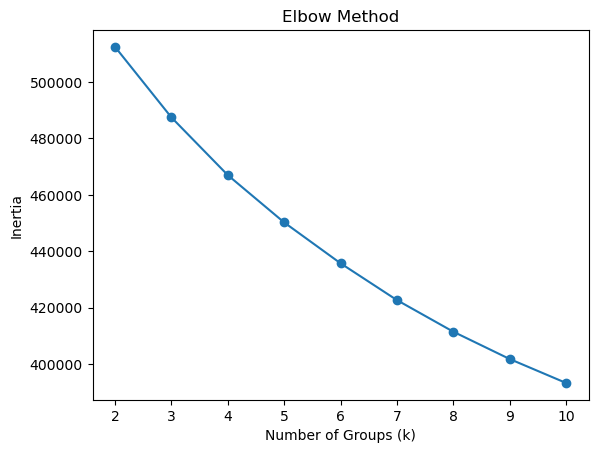

In [9]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
inertia_values = []

# Try K = 2 to 10
for k in range(2,11):

    # Create K-Means model
    Kmeans = KMeans(n_init=10,n_clusters=k,random_state=42)

    # Run K-Means on our scaled data
    Kmeans.fit(scaled_df)

    # Save the inertia
    inertia_values.append(Kmeans.inertia_)


# Draw the Elbow graph
plt.plot(range(2,11),inertia_values, marker ="o")

plt.xlabel("Number of Groups (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [35]:
# Elbow Method: No clear elbow is visible, so we will use Silhouette Score to choose the best K.

In [36]:
from sklearn.metrics import silhouette_score

silhouette_values = []

# Try K = 2 to 10
for k in range(2,11):

    # Create K-Means model
    Kmeans = KMeans(n_init=10,n_clusters=k,random_state=42)

    # Assign every user to a group
    labels = Kmeans.fit_predict(scaled_df)

    # Calculate Silhouette Score
    score = silhouette_score(scaled_df,labels)

    # Save the score
    silhouette_values.append(score)


print(silhouette_values)

KeyboardInterrupt: 

In [27]:
# OLD: Full-data Silhouette calculation was too slow.
# Used 5,000-user sample instead.

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Take 5,000 users randomly for faster Silhouette calculation
sample_df = scaled_df.sample(n=5000, random_state=42)

silhouette_values = []

# Try K = 2 to 10
for k in range(2, 11):

    # Create K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Find the groups and assign each user to a group
    labels = kmeans.fit_predict(sample_df)

    # Calculate Silhouette Score
    score = silhouette_score(sample_df, labels)

    # Save the score
    silhouette_values.append(score)

# Show the scores
for k, score in zip(range(2, 11), silhouette_values):
    print(f"K = {k}: Silhouette Score = {score:.4f}")

K = 2: Silhouette Score = 0.0709
K = 3: Silhouette Score = 0.0658
K = 4: Silhouette Score = 0.0627
K = 5: Silhouette Score = 0.0627
K = 6: Silhouette Score = 0.0626
K = 7: Silhouette Score = 0.0639
K = 8: Silhouette Score = 0.0642
K = 9: Silhouette Score = 0.0628
K = 10: Silhouette Score = 0.0630


In [24]:
# Create the final K-Means model with K = 2
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Assign every user to Group 0 or Group 1
df["cluster"] = final_kmeans.fit_predict(scaled_df)

# Check how many users are in each group
print(df["cluster"].value_counts())

cluster
0    25073
1    24927
Name: count, dtype: int64


In [25]:
# Compare the average values of each group
cluster_summary = df.groupby("cluster")[behavior_cols].mean()

print(cluster_summary)

         sessions_per_week  avg_session_duration_min  daily_active_minutes  \
cluster                                                                      
0                 7.999681                 13.090373             45.155410   
1                 7.999679                 13.209659             45.173717   

         feature_clicks_per_session  notifications_opened_per_week  \
cluster                                                              
0                         12.022933                       4.990428   
1                         12.004854                       5.002848   

         in_app_search_count  pages_viewed_per_session  content_downloads  \
cluster                                                                     
0                   4.005663                  7.986799           3.007897   
1                   3.992418                 18.986842           2.996590   

         social_shares  engagement_score  churn_risk_score  
cluster                             

In [26]:
print(df.shape)

(50000, 26)


C:\Users\Admin\AppData\Local\Temp\ipykernel_14196\666022234.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


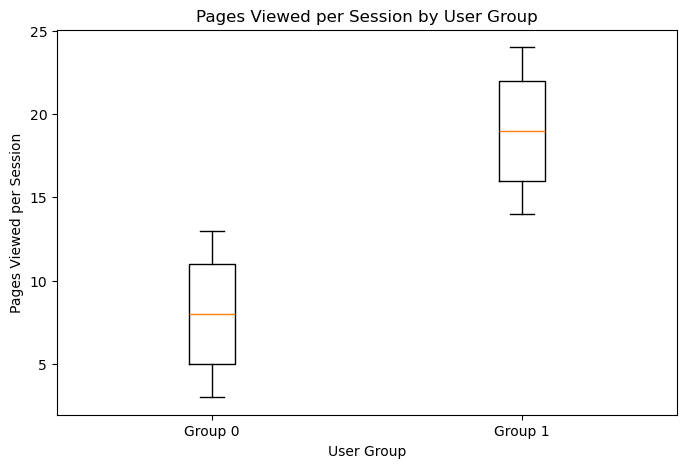

In [29]:
import matplotlib.pyplot as plt

# Create a figure and set its size.
# 8 = width and 5 = height of the graph.
plt.figure(figsize=(8, 5))

# Compare the distribution of pages viewed per session
# between Group 0 and Group 1.
# The first data set belongs to Group 0 and the second to Group 1.
plt.boxplot(
    [
        df[df["cluster"] == 0]["pages_viewed_per_session"],
        df[df["cluster"] == 1]["pages_viewed_per_session"]
    ],
    
    # Give names to the two boxes so we know which group each box represents.
    labels=["Group 0", "Group 1"]
)

plt.xlabel("User Group")
plt.ylabel("Pages Viewed per Session")
plt.title("Pages Viewed per Session by User Group")

plt.show()

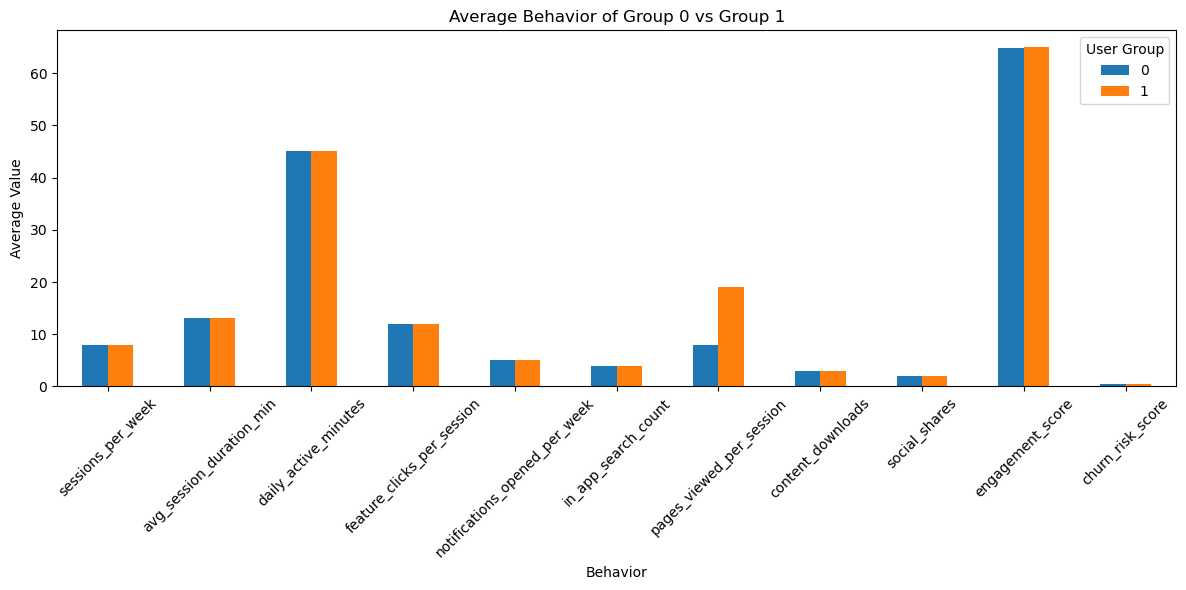

In [30]:
# Transpose the summary so that each behavior becomes a row
# and Group 0 / Group 1 become the two values we compare.
# Then create a bar chart to visually compare the average behavior
# of the two user groups.
cluster_summary.T.plot(kind="bar", figsize=(12, 6))

plt.title("Average Behavior of Group 0 vs Group 1")
plt.xlabel("Behavior")
plt.ylabel("Average Value")

# Rotate the behavior names so they are easier to read.
plt.xticks(rotation=45)

plt.legend(title="User Group")
plt.tight_layout()
plt.show()

In [31]:
#Printing for reference
print(cluster_summary.head())

         sessions_per_week  avg_session_duration_min  daily_active_minutes  \
cluster                                                                      
0                 7.999681                 13.090373             45.155410   
1                 7.999679                 13.209659             45.173717   

         feature_clicks_per_session  notifications_opened_per_week  \
cluster                                                              
0                         12.022933                       4.990428   
1                         12.004854                       5.002848   

         in_app_search_count  pages_viewed_per_session  content_downloads  \
cluster                                                                     
0                   4.005663                  7.986799           3.007897   
1                   3.992418                 18.986842           2.996590   

         social_shares  engagement_score  churn_risk_score  
cluster                             

In [32]:
# Calculate the difference between Group 0 and Group 1
# for each behavior.
# This helps us identify which behaviors separate the two groups the most.

difference = (cluster_summary.loc[1] - cluster_summary.loc[0]).abs()

# Sort from the biggest difference to the smallest difference.
difference = difference.sort_values(ascending=False)

print(difference)

pages_viewed_per_session         11.000043
avg_session_duration_min          0.119286
engagement_score                  0.065928
daily_active_minutes              0.018307
feature_clicks_per_session        0.018079
in_app_search_count               0.013246
notifications_opened_per_week     0.012420
content_downloads                 0.011307
social_shares                     0.008552
churn_risk_score                  0.000822
sessions_per_week                 0.000002
dtype: float64


In [ ]:
"""Our K-Means result is basically saying:

The two groups are almost identical in most behaviors. The major difference is how many pages they view during a session.

This also explains our earlier low Silhouette Score (0.0709).

The groups aren't strongly separated across many dimensions. """

"""For example, could we describe them as:

 Group 0 → lower page-view users
 Group 1 → higher page-view users

 Then we need to check whether things like subscription type, device, country, marketing source, etc. are different between these groups.
"""

## Group Profiling

In [36]:
# We are trying to understand what kind of users are in Group 0 and Group 1.

In [33]:
# Count how many users from each subscription type
# are present in Group 0 and Group 1.
subscription_by_group = pd.crosstab(df['cluster'],df['subscription_type'])
print(subscription_by_group)

subscription_type  Basic   Free  Premium
cluster                                 
0                   6371  15009     3693
1                   6124  15079     3724


In [34]:
# Count the different device types inside each K-Means group.
# This helps us check whether device type is different between Group 0 and Group 1.

device_by_group = pd.crosstab(
    df["cluster"],
    df["device_type"]
)

print(device_by_group)

device_type  Android   Web   iOS
cluster                         
0              13650  2549  8874
1              13665  2474  8788


In [35]:
# Count the different gender categories inside each K-Means group.
# This helps us check whether gender is different between Group 0 and Group 1.

gender_by_group = pd.crosstab(
    df["cluster"],
    df["gender"]
)

print(gender_by_group)

gender   Female   Male  Other
cluster                      
0         12035  12013   1025
1         11959  11923   1045


In [37]:
# Count users from each country inside Group 0 and Group 1.
# This helps us check whether country is different between the two groups.

country_by_group = pd.crosstab(
    df["cluster"],
    df["country"]
)

print(country_by_group)

country  Australia  Canada  Germany  India  Singapore    UK   USA
cluster                                                          
0             1764    1871     1749  11369       1258  2483  4579
1             1734    1982     1676  11181       1258  2560  4536


In [38]:
# Count users from each marketing source inside Group 0 and Group 1.
# This helps us check whether marketing source is different between the two groups.

marketing_by_group = pd.crosstab(
    df["cluster"],
    df["marketing_source"]
)

print(marketing_by_group)

marketing_source  Email Campaign  Facebook Ads  Google Ads  Organic  Referral
cluster                                                                      
0                           2522          3785        6233     8719      3814
1                           2469          3678        6235     8820      3725


In [ ]:
# Compare the average engagement and churn risk
# between Group 0 and Group 1.
# This helps us understand whether the two groups
# differ in user engagement or likelihood of leaving.

engagement_churn_by_group = df.groupby("cluster")[
    ["engagement_score", "churn_risk_score"]
].mean()

print(engagement_churn_by_group)

         engagement_score  churn_risk_score
cluster                                    
0               64.907541          0.501244
1               64.973469          0.500422


# Hierarchical Clustering

In [8]:
# Take a sample of 2,000 users from the scaled behavioral data.
# We use a sample because hierarchical clustering can be expensive
# when the dataset contains a large number of users.
# random_state=42 makes sure we get the same sample every time.

sample_df = scaled_df.sample(n=2000, random_state=42)



In [ ]:
# Create the linkage matrix using Ward's method for hierarchical clustering

from scipy.cluster.hierarchy import linkage

linked = linkage(sample_df, method='ward')

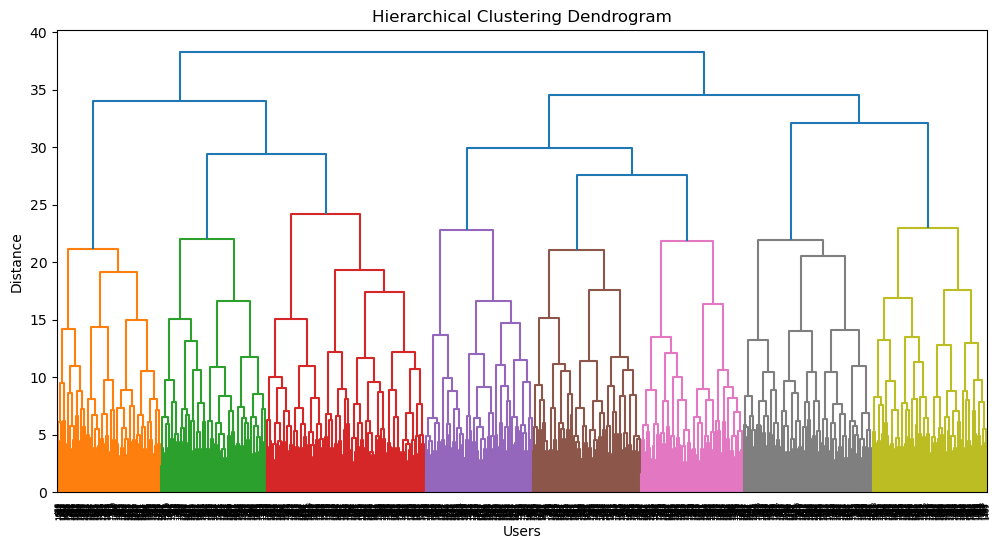

In [10]:
# Visualize the hierarchical clustering process using a dendrogram

from scipy.cluster.hierarchy import dendrogram
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))

dendrogram(linked)

plt.xlabel("Users")
plt.ylabel("Distance")
plt.title("Hierarchical Clustering Dendrogram")

plt.show()

In [13]:
sample_df.head()

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
33553,-0.353317,1.539106,0.723175,0.570671,0.896304,-1.000659,-1.020050,0.576129,-0.001019,1.171236,-0.314768
9427,0.353544,1.008193,-0.562142,2.007348,0.896304,0.000471,1.502188,1.153562,-0.001019,0.347038,-1.181093
199,-1.413609,0.750002,-0.066882,1.432677,-1.340675,-1.000659,0.398709,0.576129,0.706485,-1.637640,-0.037544
12447,1.060405,-0.338649,0.166392,-0.291335,1.343700,0.000471,-1.650609,-1.156172,1.413988,0.460930,0.967393
39489,-0.353317,-0.709729,-0.870269,0.283336,-1.340675,-1.000659,-0.862410,-1.156172,-1.416026,-0.004745,-0.453380


In [11]:
sample_df.shape

(5000, 11)

In [12]:
# Apply Agglomerative Clustering with 2 clusters using Ward linkage
# and assign each user to a hierarchical cluster.

from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

sample_df['hierarchical_cluster'] = hc.fit_predict(sample_df)

In [13]:
# Check the number of users assigned to each hierarchical cluster
# to understand how the users are distributed between the clusters.

sample_df['hierarchical_cluster'].value_counts()

hierarchical_cluster
0    3102
1    1898
Name: count, dtype: int64

In [14]:
# Calculate the Silhouette Score to check how well the two clusters are separated.
# We exclude the cluster column because it is the result, not a feature.

from sklearn.metrics import silhouette_score

score = silhouette_score(
    sample_df.drop(columns='hierarchical_cluster'),
    sample_df['hierarchical_cluster']
)

print("Hierarchical Clustering Silhouette Score:", score)

Hierarchical Clustering Silhouette Score: 0.043159074428009495


In [15]:
sample_df.shape

(5000, 12)

In [17]:
# Create a fresh sample of exactly 2,000 users.
sample_df = scaled_df.sample(n=2000, random_state=42)

print(sample_df.shape)

(2000, 11)


# DB SCAN

## K-Distance Plot

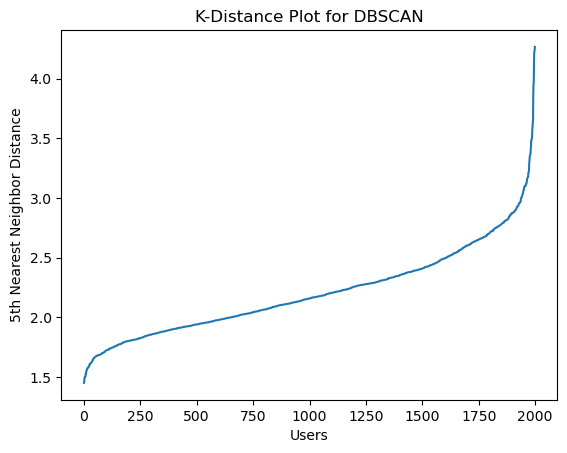

In [18]:
# Create a k-distance plot to help choose a suitable eps value for DBSCAN.
# We calculate the distance to each user's 5th nearest neighbor.

from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(sample_df)

distances, indices = neighbors_fit.kneighbors(sample_df)

distances = distances[:, 4]
distances = sorted(distances)

plt.plot(distances)
plt.xlabel("Users")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Plot for DBSCAN")
plt.show()

In [19]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Create DBSCAN model
dbscan = DBSCAN(
    eps=2.8,          # Maximum distance to consider another point as a neighbor
    min_samples=5     # Minimum number of points needed to form a dense area
)

# Assign a cluster number to every user
dbscan_labels = dbscan.fit_predict(sample_df)

# Add the cluster labels to our dataframe
sample_df['DBSCAN_Cluster'] = dbscan_labels

# Display the cluster values
print(sample_df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    1964
-1      36
Name: count, dtype: int64


In [20]:
from sklearn.cluster import DBSCAN

# Try a slightly larger eps value
dbscan = DBSCAN(
    eps=2.9,
    min_samples=5
)

# Generate cluster labels
dbscan_labels = dbscan.fit_predict(sample_df)

# Store the labels
sample_df['DBSCAN_Cluster'] = dbscan_labels

# See how many users are in each cluster
print(sample_df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    1965
-1      35
Name: count, dtype: int64


In [21]:
from sklearn.cluster import DBSCAN

# Try a slightly larger eps value
dbscan = DBSCAN(
    eps=3.0,
    min_samples=5
)

# Generate cluster labels
dbscan_labels = dbscan.fit_predict(sample_df)

# Store the labels
sample_df['DBSCAN_Cluster'] = dbscan_labels

# See how many users are in each cluster
print(sample_df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    1968
-1      32
Name: count, dtype: int64


In [22]:
from sklearn.cluster import DBSCAN

# Create DBSCAN model
dbscan = DBSCAN(
    eps=2.8,          # Maximum distance for points to be considered neighbors
    min_samples=10    # Minimum number of nearby points needed to form a cluster
)

# Run DBSCAN and get the cluster label for each user
dbscan_labels = dbscan.fit_predict(sample_df)

# Add the DBSCAN cluster labels to our dataframe
sample_df['DBSCAN_Cluster'] = dbscan_labels

# Count how many users are in each cluster
# -1 means the user was classified as noise/outlier
print(sample_df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    1959
-1      41
Name: count, dtype: int64


In [23]:
print(sample_df.columns)

Index(['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
       'feature_clicks_per_session', 'notifications_opened_per_week',
       'in_app_search_count', 'pages_viewed_per_session', 'content_downloads',
       'social_shares', 'engagement_score', 'churn_risk_score',
       'DBSCAN_Cluster'],
      dtype='object')


In [10]:
# List of the user behavior features
features = [
    'sessions_per_week',
    'avg_session_duration_min',
    'daily_active_minutes',
    'feature_clicks_per_session',
    'notifications_opened_per_week',
    'in_app_search_count',
    'pages_viewed_per_session',
    'content_downloads',
    'social_shares',
    'engagement_score',
    'churn_risk_score'
]

# Select only these features for DBSCAN
X = sample_df[features]

# Check the number of rows and columns
print(X.shape)

(5000, 11)


In [11]:
# Take the same 2,000 users from the scaled dataset
# random_state=42 makes sure we get the same sample every time
sample_X = scaled_df.sample(n=2000, random_state=42)

# Check the shape
print(sample_X.shape)

(2000, 11)


In [12]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd

# Try several eps values while keeping min_samples fixed
# This helps us understand how eps changes the clustering
eps_values = [1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0]

results = []

for eps in eps_values:

    # Create DBSCAN model
    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )

    # Run DBSCAN only on our clean 2000 x 11 dataset
    labels = dbscan.fit_predict(sample_X)

    # Count noise points (-1)
    noise_count = (labels == -1).sum()

    # Find actual number of clusters
    # -1 is noise, so we don't count it
    unique_labels = set(labels)
    n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)

    # Calculate noise percentage
    noise_percentage = (noise_count / len(labels)) * 100

    # Silhouette needs at least 2 actual clusters
    if n_clusters >= 2:
        mask = labels != -1

        silhouette = silhouette_score(
            sample_X[mask],
            labels[mask]
        )
    else:
        silhouette = None

    # Store the results
    results.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise_count": noise_count,
        "noise_percentage": round(noise_percentage, 2),
        "silhouette_score": silhouette
    })

# Convert results into a table
results_df = pd.DataFrame(results)

print(results_df)

   eps  clusters  noise_count  noise_percentage  silhouette_score
0  1.8        16         1488             74.40         -0.148013
1  2.0         3          868             43.40         -0.003577
2  2.2         3          464             23.20          0.043368
3  2.4         1          216             10.80               NaN
4  2.6         1           94              4.70               NaN
5  2.8         1           36              1.80               NaN
6  3.0         1           19              0.95               NaN


In [16]:
type(sample_X)

pandas.core.frame.DataFrame

In [15]:
sample_X.shape

(2000, 11)

# Run final K-Means with k = 2

In [17]:
from sklearn.cluster import KMeans

# Create the final K-Means model with 2 clusters
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

# Assign each user to Cluster 0 or Cluster 1
cluster_labels = kmeans.fit_predict(sample_X)

# Add the cluster labels to our dataset
sample_X["Cluster"] = cluster_labels

In [18]:
sample_X["Cluster"].value_counts()

Cluster
0    1027
1     973
Name: count, dtype: int64

In [19]:
#We want to calculate the average value of each behavior feature for Cluster 0 and Cluster 1.
cluster_profile = sample_X.groupby("Cluster").mean()
cluster_profile

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
Cluster,,,,,,,,,,,
0,-0.013308,0.026455,-0.016106,-0.068349,-0.078644,-0.047295,0.004533,-0.066526,-0.012730,0.090652,-0.872827
1,0.038980,-0.001518,0.108140,0.068646,0.195552,-0.026796,-0.015561,0.114419,0.045518,-0.140932,0.824542


# Profile the clusters using the original data.

#

In [20]:
# Make a copy of the original user data
behavior_clustered = behavior_df.copy()

# Add the final K-Means cluster for each user
behavior_clustered["Cluster"] = cluster_labels

# Calculate the average original values for each cluster
original_cluster_profile = behavior_clustered.groupby("Cluster").mean()

original_cluster_profile

ValueError: Length of values (2000) does not match length of index (50000)

In [21]:
# Select the same 2000 users that were used for K-Means
behavior_clustered = behavior_df.loc[sample_X.index].copy()

# Add their K-Means cluster labels
behavior_clustered["Cluster"] = cluster_labels

# Calculate the average original values for each cluster
original_cluster_profile = behavior_clustered.groupby("Cluster")[behavior_cols].mean()

original_cluster_profile

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
Cluster,,,,,,,,,,,
0,7.962025,13.386534,44.850399,11.776047,4.820837,3.904576,13.499513,2.887050,1.983447,66.285570,0.248958
1,8.109969,13.136259,47.273792,12.252826,5.433710,3.945529,13.372045,3.200411,2.065776,62.849168,0.738777


In [22]:
print("behavior_df shape:", behavior_df.shape)
print("scaled_df shape:", scaled_df.shape)
print("sample_X shape:", sample_X.shape)

print("behavior_df index:", behavior_df.index[:5])
print("scaled_df index:", scaled_df.index[:5])
print("sample_X index:", sample_X.index[:5])

behavior_df shape: (50000, 11)
scaled_df shape: (50000, 11)
sample_X shape: (2000, 12)
behavior_df index: RangeIndex(start=0, stop=5, step=1)
scaled_df index: RangeIndex(start=0, stop=5, step=1)
sample_X index: Index([33553, 9427, 199, 12447, 39489], dtype='int64')


# Apply the final K-Means model to ALL 50,000 users (Cluster Assignment)

In [10]:
from sklearn.cluster import KMeans

# Create the final K-Means model with 2 clusters
final_kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Train K-Means on all 50,000 users
full_cluster_labels = final_kmeans.fit_predict(scaled_df)

# Add the cluster labels to the original dataset
behavior_clustered = behavior_df.copy()
behavior_clustered["Cluster"] = full_cluster_labels

# Check how many users are in each cluster
behavior_clustered["Cluster"].value_counts()

Cluster
0    25073
1    24927
Name: count, dtype: int64

In [24]:
# Calculate the average behavior of users in each final cluster
final_cluster_profile = behavior_clustered.groupby("Cluster")[behavior_cols].mean()

final_cluster_profile

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
Cluster,,,,,,,,,,,
0,7.999681,13.090373,45.155410,12.022933,4.990428,4.005663,7.986799,3.007897,2.005703,64.907541,0.501244
1,7.999679,13.209659,45.173717,12.004854,5.002848,3.992418,18.986842,2.996590,1.997152,64.973469,0.500422


In [25]:
behavior_df["pages_viewed_per_session"].describe()

count    50000.000000
mean        13.470760
std          6.343635
min          3.000000
25%          8.000000
50%         13.000000
75%         19.000000
max         24.000000
Name: pages_viewed_per_session, dtype: float64

In [28]:
behavior_df["pages_viewed_per_session"].value_counts().sort_index()

pages_viewed_per_session
3     2293
4     2292
5     2259
6     2373
7     2205
8     2248
9     2272
10    2293
11    2393
12    2232
13    2213
14    2298
15    2211
16    2320
17    2338
18    2235
19    2238
20    2247
21    2249
22    2304
23    2215
24    2272
Name: count, dtype: int64

## Cluster-Level User Identification & Profiling

In [29]:
print(behavior_clustered.columns)

Index(['sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
       'feature_clicks_per_session', 'notifications_opened_per_week',
       'in_app_search_count', 'pages_viewed_per_session', 'content_downloads',
       'social_shares', 'engagement_score', 'churn_risk_score', 'Cluster'],
      dtype='object')


In [30]:
# Check the variables/dataframes currently available
%whos DataFrame

Variable                   Type         Data/Info
-------------------------------------------------
X                          DataFrame    Shape: (5000, 11)
behavior_clustered         DataFrame    Shape: (50000, 12)
behavior_df                DataFrame    Shape: (50000, 11)
cluster_profile            DataFrame    Shape: (2, 11)
df                         DataFrame    Shape: (50000, 25)
final_cluster_profile      DataFrame    Shape: (2, 11)
original_cluster_profile   DataFrame    Shape: (2, 11)
results_df                 DataFrame    Shape: (7, 5)
sample_X                   DataFrame    Shape: (2000, 12)
sample_df                  DataFrame    Shape: (5000, 11)
scaled_df                  DataFrame    Shape: (50000, 11)


In [31]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'device_type', 'app_version',
       'sessions_per_week', 'avg_session_duration_min', 'daily_active_minutes',
       'feature_clicks_per_session', 'notifications_opened_per_week',
       'in_app_search_count', 'pages_viewed_per_session',
       'crash_events_last_30_days', 'support_tickets_raised',
       'days_since_last_login', 'subscription_type',
       'ads_clicked_last_30_days', 'content_downloads', 'social_shares',
       'rating_given', 'churn_risk_score', 'engagement_score',
       'account_age_days', 'marketing_source'],
      dtype='object')


In [32]:
# Combine user_id with the final cluster assigned to each user
user_clusters = df[["user_id"]].copy()
user_clusters["Cluster"] = behavior_clustered["Cluster"].values

# View the first few users
user_clusters.head()

,user_id,Cluster
0,100000,0
1,100001,0
2,100002,1
3,100003,0
4,100004,1


### Cluster Profiling

In [33]:
# Calculate the average behavior of users in each cluster
final_cluster_profile = behavior_clustered.groupby("Cluster")[behavior_cols].mean()

final_cluster_profile

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
Cluster,,,,,,,,,,,
0,7.999681,13.090373,45.155410,12.022933,4.990428,4.005663,7.986799,3.007897,2.005703,64.907541,0.501244
1,7.999679,13.209659,45.173717,12.004854,5.002848,3.992418,18.986842,2.996590,1.997152,64.973469,0.500422


In [34]:
# Count the number of users in each cluster
cluster_counts = behavior_clustered["Cluster"].value_counts().sort_index()
cluster_counts

Cluster
0    25073
1    24927
Name: count, dtype: int64

In [35]:
# Get the users belonging to each cluster
cluster_0_users = user_clusters[user_clusters["Cluster"] == 0]
cluster_1_users = user_clusters[user_clusters["Cluster"] == 1]

# Count users in each cluster
print("Cluster 0 users:", len(cluster_0_users))
print("Cluster 1 users:", len(cluster_1_users))

Cluster 0 users: 25073
Cluster 1 users: 24927


In [36]:
# Create a simple profile with the main business-related metrics
customer_profiles = final_cluster_profile[
    [
        "sessions_per_week",
        "avg_session_duration_min",
        "daily_active_minutes",
        "pages_viewed_per_session",
        "engagement_score",
        "churn_risk_score"
    ]
]

customer_profiles

,sessions_per_week,avg_session_duration_min,daily_active_minutes,pages_viewed_per_session,engagement_score,churn_risk_score
Cluster,,,,,,
0,7.999681,13.090373,45.155410,7.986799,64.907541,0.501244
1,7.999679,13.209659,45.173717,18.986842,64.973469,0.500422


## Business Insight Generation & Customer Action Mapping

In [ ]:
# Create a copy of the final cluster profile
business_summary = final_cluster_profile.copy()

# Add the number of users in each cluster
business_summary["customer_count"] = cluster_counts

# Calculate the percentage of total users in each cluster
business_summary["customer_percentage"] = (
    business_summary["customer_count"] / len(behavior_clustered) * 100
)

# Display the final business summary
business_summary

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score,customer_count,customer_percentage
Cluster,,,,,,,,,,,,,
0,7.999681,13.090373,45.155410,12.022933,4.990428,4.005663,7.986799,3.007897,2.005703,64.907541,0.501244,25073,50.146
1,7.999679,13.209659,45.173717,12.004854,5.002848,3.992418,18.986842,2.996590,1.997152,64.973469,0.500422,24927,49.854


In [38]:
# Compare the difference between the two clusters for all 11 features
cluster_difference = final_cluster_profile.loc[1] - final_cluster_profile.loc[0]

cluster_difference.sort_values(key=abs, ascending=False)

pages_viewed_per_session         11.000043
avg_session_duration_min          0.119286
engagement_score                  0.065928
daily_active_minutes              0.018307
feature_clicks_per_session       -0.018079
in_app_search_count              -0.013246
notifications_opened_per_week     0.012420
content_downloads                -0.011307
social_shares                    -0.008552
churn_risk_score                 -0.000822
sessions_per_week                -0.000002
dtype: float64

In [39]:
# Create a simple summary of the main business insight for each cluster
business_insights = pd.DataFrame({
    "Cluster": [0, 1],
    "User Count": [25073, 24927],
    "Pages Viewed per Session": [
        final_cluster_profile.loc[0, "pages_viewed_per_session"],
        final_cluster_profile.loc[1, "pages_viewed_per_session"]
    ],
    "Engagement Score": [
        final_cluster_profile.loc[0, "engagement_score"],
        final_cluster_profile.loc[1, "engagement_score"]
    ],
    "Churn Risk Score": [
        final_cluster_profile.loc[0, "churn_risk_score"],
        final_cluster_profile.loc[1, "churn_risk_score"]
    ]
})

business_insights

,Cluster,User Count,Pages Viewed per Session,Engagement Score,Churn Risk Score
0,0,25073,7.986799,64.907541,0.501244
1,1,24927,18.986842,64.973469,0.500422


### Business Insights

* **Cluster 1 as a high-value customer segment:** Cluster 1 contains 24,927 users (49.854%) and shows approximately 19 pages viewed per session, compared with approximately 8 pages in Cluster 0. This deeper browsing behavior can be considered an indicator of stronger user interaction with the app.
* These users can be targeted with **loyalty benefits, premium offers, personalized recommendations, and exclusive features** to maintain their engagement and encourage continued usage.

* **Low-engagement users for retention:** The `engagement_score` column in the raw dataset was analyzed by calculating its minimum, maximum, and overall average value. Users with an engagement score **below the overall average** were identified as low-engagement users and can be considered for retention campaigns.
* The analysis identified **5 users below the average engagement score**:

| User ID | Engagement Score |
|---:|---:|
| 100000 | 55.79 |
| 100002 | 42.49 |
| 100003 | 62.81 |
| 100004 | 38.21 |
| 100006 | 63.30 |

* These users can be targeted with **personalized reminders, relevant content recommendations, special offers, and engagement-focused notifications** to encourage continued app usage.

* **Personalized strategies for moderate users:** Cluster 0 contains approximately 25,073 users (50.146%) and has lower browsing depth, with around 8 pages viewed per session. Compared with Cluster 1, these users can be treated as the **moderate/lower-browsing segment**.
* Personalized recommendations, better content discovery, improved navigation, feature suggestions, and relevant prompts can be used to encourage these users to explore more pages and interact more deeply with the app.
* The objective is to improve the browsing and interaction behavior of Cluster 0 users toward the stronger browsing pattern observed in Cluster 1.

* **Marketing, product, and retention decisions:** The identified customer segments can help different business teams make behavior-based decisions instead of applying the same strategy to all users.
  * **Marketing:** Create segment-specific campaigns and offers based on user behavior.
  * **Product:** Identify differences between the segments and improve content discovery, navigation, recommendations, and other app features.
  * **Retention:** Use the raw engagement analysis to identify below-average engagement users and target them with suitable retention strategies.

* **Customer-level targeting:** Since each user has a `user_id` and an assigned cluster, individual customers can be identified and targeted according to their behavioral segment.
* This enables the business to move from **generic campaigns for all users** to more personalized actions, such as premium/loyalty strategies for Cluster 1 users, engagement-improvement strategies for Cluster 0 users, and retention campaigns for users with below-average engagement.

## PCA Visualization of Clusters

In [11]:
from sklearn.decomposition import PCA

# Reduce the 11 behavioral features to 2 principal components
pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_df)

# Create a DataFrame containing the two PCA components
pca_df = pd.DataFrame(
    pca_data,
    columns=["PC1", "PC2"]
)

# Add the final cluster assigned to each user
pca_df["Cluster"] = behavior_clustered["Cluster"].values

# Display the first few rows
pca_df.head()

,PC1,PC2,Cluster
0,0.079711,-0.307223,0
1,0.237653,-0.672567,0
2,1.349435,0.587627,1
3,1.209279,0.703234,0
4,0.729772,1.288610,1


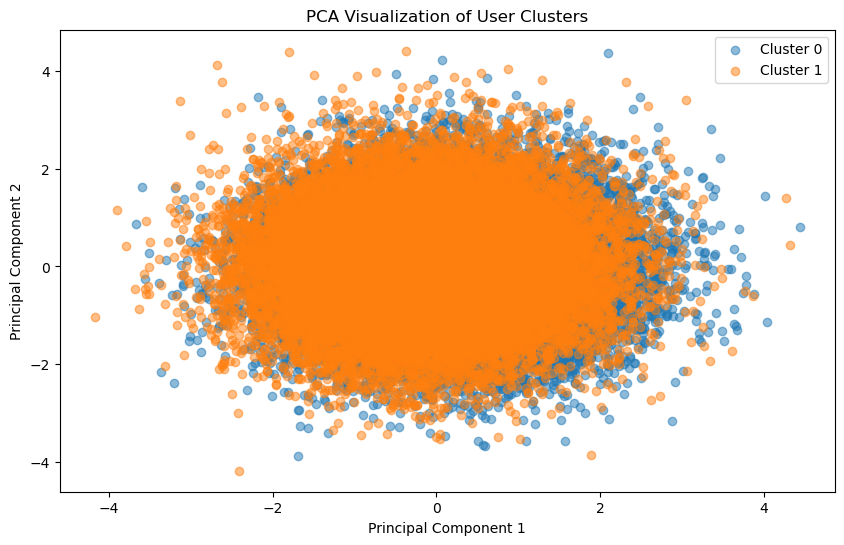

In [12]:
import matplotlib.pyplot as plt

# Plot users based on the two PCA components
plt.figure(figsize=(10, 6))

for cluster in sorted(pca_df["Cluster"].unique()):
    # Select only the users belonging to the current cluster
    cluster_data = pca_df[pca_df["Cluster"] == cluster]

    # Plot that cluster on the PCA graph
    plt.scatter(
        cluster_data["PC1"],
        cluster_data["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.5
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Visualization of User Clusters")
plt.legend()
plt.show()

In [13]:
# Check how much variance is retained by the two PCA components
print("PC1 variance explained:", pca.explained_variance_ratio_[0])
print("PC2 variance explained:", pca.explained_variance_ratio_[1])
print("Total variance explained:", pca.explained_variance_ratio_.sum())

PC1 variance explained: 0.09268547453032326
PC2 variance explained: 0.09211663949149952
Total variance explained: 0.18480211402182278


### PCA Interpretation

The first principal component explains 9.27% of the total variance, while the second principal component explains 9.21%. Together, the two components explain 18.48% of the total variance.

The PCA scatter plot shows substantial overlap between Cluster 0 and Cluster 1. Since the first two principal components capture only 18.48% of the total variance, the 2D PCA visualization provides a limited representation of the original 11-dimensional feature space and should be treated as a visualization rather than a clustering-quality measure.

## Cluster Size Visualization

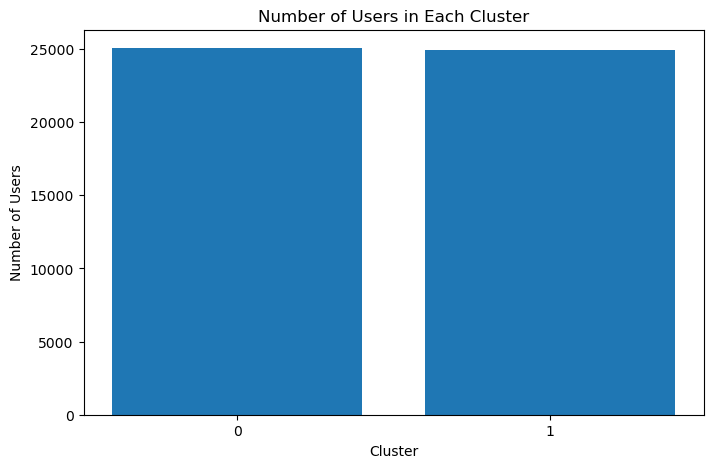

In [15]:
import matplotlib.pyplot as plt

# Count the number of users in each cluster
cluster_counts = behavior_clustered["Cluster"].value_counts().sort_index()

# Plot the cluster sizes
plt.figure(figsize=(8, 5))
plt.bar(cluster_counts.index.astype(str), cluster_counts.values)

plt.xlabel("Cluster")
plt.ylabel("Number of Users")
plt.title("Number of Users in Each Cluster")
plt.show()

## Cluster Behavior Comparison

In [16]:
# Calculate standardized average behavior for each cluster
cluster_profile_scaled = behavior_clustered.groupby("Cluster")[behavior_cols].mean()

cluster_profile_scaled

,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
Cluster,,,,,,,,,,,
0,7.999681,13.090373,45.155410,12.022933,4.990428,4.005663,7.986799,3.007897,2.005703,64.907541,0.501244
1,7.999679,13.209659,45.173717,12.004854,5.002848,3.992418,18.986842,2.996590,1.997152,64.973469,0.500422


In [17]:
# Add the final cluster labels to the scaled data
scaled_clustered = scaled_df.copy()
scaled_clustered["Cluster"] = behavior_clustered["Cluster"].values

# Calculate the average standardized value for each cluster
cluster_profile_scaled = scaled_clustered.groupby("Cluster")[behavior_cols].mean()

# Display the scaled cluster profiles
cluster_profile_scaled


,sessions_per_week,avg_session_duration_min,daily_active_minutes,feature_clicks_per_session,notifications_opened_per_week,in_app_search_count,pages_viewed_per_session,content_downloads,social_shares,engagement_score,churn_risk_score
Cluster,,,,,,,,,,,
0,3.292840e-07,-0.006647,-0.000468,0.002590,-0.002770,0.003305,-0.864491,0.003255,0.003016,-0.002215,0.001419
1,-3.312127e-07,0.006686,0.000471,-0.002605,0.002787,-0.003325,0.869555,-0.003274,-0.003034,0.002228,-0.001428


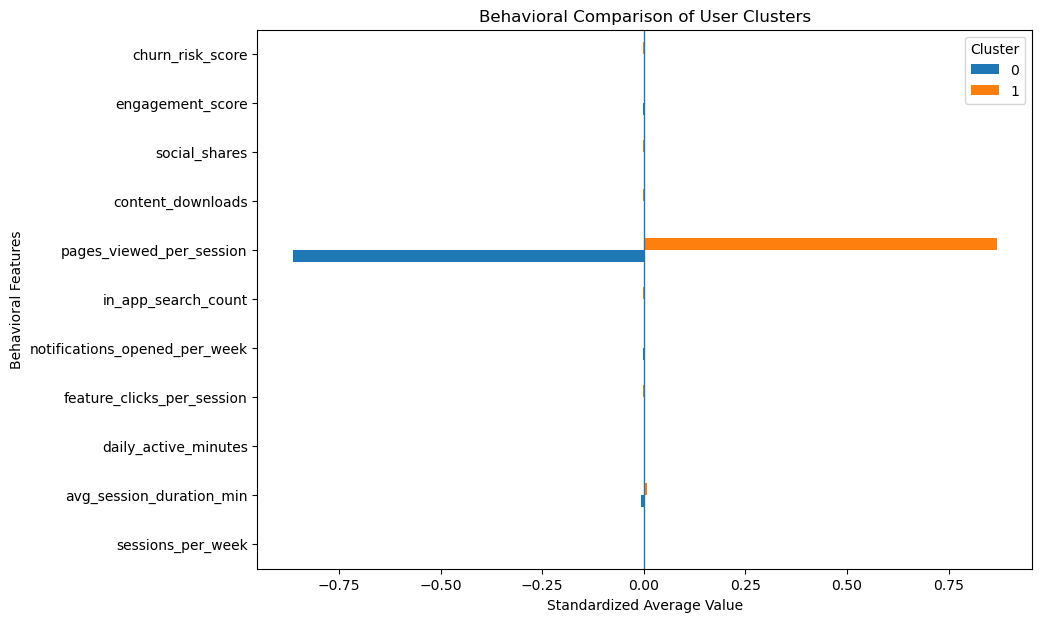

In [18]:
import matplotlib.pyplot as plt

# Transpose the cluster profile so features appear on the y-axis
plot_data = cluster_profile_scaled.T

# Plot the standardized average of each feature for both clusters
plot_data.plot(kind="barh", figsize=(10, 7))

plt.xlabel("Standardized Average Value")
plt.ylabel("Behavioral Features")
plt.title("Behavioral Comparison of User Clusters")
plt.axvline(0, linewidth=1)
plt.legend(title="Cluster")
plt.show()